# PRO/PAO phase demo

In [ ]:
"""
File Name: pro_pao_phase.ipynb

Author:
    Federico Minati
    B-Open Solutions srl

Date: August 2025

Description:
------------
This notebook processes Sentinel-1 data to generate Analysis-Ready Data (ARD) products, specifically Precise azimuth offset.
Options and configuration parameters about some processing steps can be set
by the user.

"""

In [4]:
import xarray as xr
import numpy as np
import pandas as pd
import os
from scipy.constants import speed_of_light
import s3fs

fs = s3fs.S3FileSystem(anon=True)

In [5]:
in_data = "s3://bopen-sar/ARD-ROSE-L/SENTINEL/Greenland/112/SENTINEL1_112_20230710_20230722_HH"
# in_data = 's3://bopen-sar/ARD-ROSE-L/SENTINEL/Greenland/119/SENTINEL1_119_20230710_20230722_HH'
dirname = os.path.dirname(in_data)
basename = os.path.basename(in_data)
ml = {"az": 16, "rg": 64}

In [ ]:
burst = xr.open_datatree(
    os.path.join(in_data, "bursts"), chunks={}, consolidate_metadata=False
)

In [4]:
az_min = []
rg_min = []
dtrg = []
dtaz = []
for _, v in burst.items():
    annot = v.coreg.cstack.attrs
    az_min.append(v.coreg.azimuth_time.min().values)
    rg_min.append(v.coreg.slant_range_time.min().values)
    dtaz.append(
        annot["RMA"]["INCA"]["TimeCAPoly"]["Coefs"][1] * annot["Grid"]["Col"]["SS"]
    )
    dtrg.append(2 * annot["Grid"]["Row"]["SS"] / speed_of_light)

az_min = np.array(az_min).min()
rg_min = np.array(rg_min).min()
dtrg = np.array(dtrg).mean()
dtaz = np.array(dtaz).mean()
az_min, rg_min, dtrg, dtaz

(numpy.datetime64('2023-07-10T09:13:48.336512634'),
 0.005658604337719389,
 1.554116558005821e-08,
 0.002055556299999998)

# Single interferogram generation

In [ ]:
os.makedirs(f"{dirname.replace('s3://','/s3/')}/phase_ml/", exist_ok=True)
for k, v in burst.items():
    coreg = v.coreg.to_dataset()
    coreg = coreg.rename({"azimuth_time": "y", "slant_range_time": "x"})
    y = np.round(
        (coreg.y.values - az_min).astype(float) / 1e9 / dtaz
    )  # multilooked pixel
    x = np.round((coreg.x.values - rg_min).astype(float) / dtrg)  # multilooked pixel
    coreg["x"] = x
    coreg["y"] = y
    interf_ml = (
        (coreg.cstack[1] * coreg.cstack[0].conj())
        .coarsen(y=ml["az"], x=ml["rg"], boundary="trim")
        .mean()
    )

    int0 = (
        (np.abs(coreg.cstack[0]) ** 2)
        .coarsen(y=ml["az"], x=ml["rg"], boundary="trim")
        .mean()
    )
    int1 = (
        (np.abs(coreg.cstack[1]) ** 2)
        .coarsen(y=ml["az"], x=ml["rg"], boundary="trim")
        .mean()
    )

    ph_ml = xr.apply_ufunc(np.angle, interf_ml, dask="parallelized")

    outfile = f"{dirname.replace('s3://','/s3/')}/phase_ml/{basename}_ph_ml_{k}_ml{ml['az']}az_{ml['rg']}rg.tif"
    ph_ml.rio.to_raster(outfile, driver="COG", dtype="float32", compress="DEFLATE")

    cohe = np.abs(interf_ml) / (np.sqrt(int0 * int1))
    cohe.rio.to_raster(
        outfile.replace("ph_ml", "cohe"),
        driver="COG",
        dtype="float32",
        compress="DEFLATE",
    )
    np.sqrt(int0 * int1).rio.to_raster(
        outfile.replace("ph_ml", "intensity_ml"),
        driver="COG",
        dtype="float32",
        compress="DEFLATE",
    )

# Burst overlap double phase difference generation (Precise azimuth offset)

In [ ]:
os.makedirs(f"{dirname.replace('s3://','/s3/')}/phase_overlap_ml/", exist_ok=True)
for iw in ["iw1", "iw2", "iw3"]:
    for k in range(0, 300_000):
        if f"{iw}_{k}" not in burst.keys():
            continue
        if f"{iw}_{k+1}" not in burst.keys():
            continue
        print(f"Processing {iw}_{k} and {iw}_{k+1}")
        v00 = burst[f"{iw}_{k}"].coreg.cstack[0].copy()
        v01 = burst[f"{iw}_{k}"].coreg.cstack[1].copy()
        v10 = burst[f"{iw}_{k+1}"].coreg.cstack[0].copy()
        v11 = burst[f"{iw}_{k+1}"].coreg.cstack[1].copy()
        y = np.round(
            (v00.azimuth_time.values - az_min).astype(float) / 1e9 / dtaz
        )  # multilooked pixel
        x = np.round(
            (v00.slant_range_time.values - rg_min).astype(float) / dtrg
        )  # multilooked pixel
        v00 = v00.drop_vars(["azimuth_time", "slant_range_time"]).rename(
            {"azimuth_time": "y", "slant_range_time": "x"}
        )
        v01 = v01.drop_vars(["azimuth_time", "slant_range_time"]).rename(
            {"azimuth_time": "y", "slant_range_time": "x"}
        )
        v00["x"] = x
        v01["x"] = x
        v00["y"] = y
        v01["y"] = y
        y = np.round(
            (v10.azimuth_time.values - az_min).astype(float) / 1e9 / dtaz
        )  # multilooked pixel
        x = np.round(
            (v10.slant_range_time.values - rg_min).astype(float) / dtrg
        )  # multilooked pixel
        v10 = v10.drop_vars(["azimuth_time", "slant_range_time"]).rename(
            {"azimuth_time": "y", "slant_range_time": "x"}
        )
        v11 = v11.drop_vars(["azimuth_time", "slant_range_time"]).rename(
            {"azimuth_time": "y", "slant_range_time": "x"}
        )
        v10["x"] = x
        v11["x"] = x
        v10["y"] = y
        v11["y"] = y

        interf_ml = (
            (v01 * v00.conj() * v11.conj() * v10)
            .coarsen(y=ml["az"], x=ml["rg"], boundary="trim")
            .mean()
        )
        ph_ml = xr.apply_ufunc(np.angle, interf_ml, dask="parallelized")
        outfile = f"{dirname.replace('s3://','/s3/')}/phase_overlap_ml/{basename}_ph_overlap_{iw}_ml_{k}_{k+1}_ml{ml['az']}az_{ml['rg']}rg.tif"
        ph_ml.rio.to_raster(outfile, driver="COG", dtype="float32", compress="DEFLATE")

        a00 = (
            (np.abs(v00 * v10) ** 2)
            .coarsen(y=ml["az"], x=ml["rg"], boundary="trim")
            .mean()
        )
        a11 = (
            (np.abs(v01 * v11) ** 2)
            .coarsen(y=ml["az"], x=ml["rg"], boundary="trim")
            .mean()
        )
        den = np.sqrt(a00 * a11)
        cohe = np.abs(interf_ml) / den
        outfile = f"{dirname.replace('s3://','/s3/')}/phase_overlap_ml/{basename}_cohe_overlap_{iw}_ml_{k}_{k+1}_ml{ml['az']}az_{ml['rg']}rg.tif"
        cohe.rio.to_raster(outfile, driver="COG", dtype="float32", compress="DEFLATE")

# coherence visualization

In [7]:
cohe

<xarray.Dataset> Size: 31kB
Dimensions:      (band: 1, x: 407, y: 17)
Coordinates:
  * band         (band) int64 8B 1
  * x            (x) float64 3kB 31.5 95.5 159.5 ... 2.595e+04 2.602e+04
  * y            (y) float64 136B 2.248e+03 2.264e+03 ... 2.488e+03 2.504e+03
    spatial_ref  int64 8B ...
Data variables:
    band_data    (band, y, x) float32 28kB ...

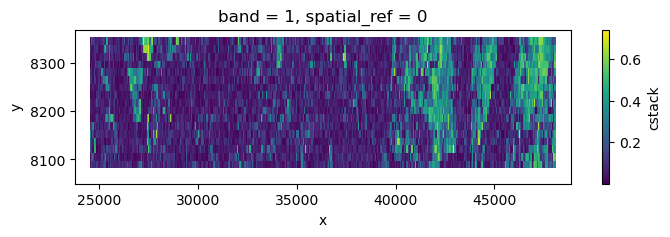

In [27]:
cohe = xr.open_dataset(
    f"s3://bopen-sar/ARD-ROSE-L/SENTINEL/Greenland/112/phase_overlap_ml/SENTINEL1_112_20230710_20230722_HH_cohe_overlap_iw3_ml_239132_239133_ml16az_64rg.tif"
)
cohe.band_data.plot(figsize=(8, 2))

# Double phase difference visualization

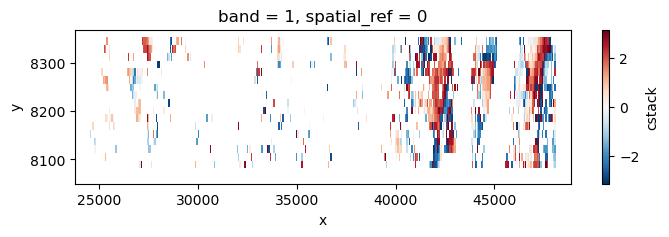

In [32]:
ph_ml = xr.open_dataset(
    f"s3://bopen-sar/ARD-ROSE-L/SENTINEL/Greenland/112/phase_overlap_ml/SENTINEL1_112_20230710_20230722_HH_ph_overlap_iw3_ml_239132_239133_ml16az_64rg.tif"
)
ph_ml.band_data.where(cohe.band_data > 0.25).plot(figsize=(8, 2))